# E12-H61 - Moved flag as a displacement-and-inversion conjunction

**Author**: Konrad Jelen (kj)<br>
**Pipeline stage**: experiment - reporting-diff channel, per-statement `moved` annotation

The shipped `moved` flag is a single-signal threshold, `abs(displacement_norm) > 0.05`
(`pipeline.py:551-553`). The two displacement signals already carried on every record fail in
complementary regimes: the raw rank `displacement` saturates under length change (DEF-TRANS-2, the
defect that produced the current norm-only definition) but is exactly `0` under any order-preserving
insertion, while `displacement_norm` is length-stable under shrinkage but drifts by about `1/n` per
inserted statement, which exceeds the fixed `0.05` band whenever `n < 19` - the regime of every
calibration summary (3-11 statements). This notebook measures the false-fire rate of the shipped
definition on an insertion fixture and scores the conjunction
`(displacement != 0) AND (abs(displacement_norm) > 0.05)` against the registered acceptance bar.

**Registered contract** (`docs/experiments/wmd-docdistance-experiments.md`, `### E12-H61`)
- **Prediction** - on the 6-statement worked-example document A with one statement inserted at the
  top of B, the shipped flag fires `moved` on 4 of 6 untouched statements (norms 6/42, 5/42, 4/42,
  3/42, all above 0.05) and the conjunction fires 0 of 6; the worked-example swap pair still fires 2
- **Acceptance bar** - PASS if the conjunction gives 0 false `moved` on the insertion fixture, keeps
  both swap statements flagged on the worked example, keeps the reversal control at 12/12, and stays
  quiet on all kept statements of a locally rebuilt 12 to 8 shrinkage synthetic; FAIL if any true
  swap or relocation in the structure-fixture reorder pool loses its flag
- **Kill-gate** - `order_alignment` on the insertion fixture must return the monotone shift
  `[1, 2, 3, 4, 5, 6]`; any non-monotone alignment kills the run, because non-zero rank displacements
  would stop the conjunction from suppressing the false fires
- **Guardrails** - detail `smd` and `order_gap` bit-identical across the two definitions, the
  transport plan untouched, `V` stays `0/24`, the metric property untouched

**Approach**
1. **Build the fixtures** - insertion, worked example, 12 to 8 shrinkage, reversal control, and the
   processed reorder pool - *why*: each named fixture of the registered bar, built once and embedded once
2. **Run the kill-gate** - the band arithmetic plus the `order_alignment` monotonicity check -
   *why*: a non-monotone alignment invalidates the whole mechanism, so it is checked before any scoring
3. **Run the harness sanity check** - the reversal control must read 12/12 under the shipped
   definition - *why*: a harness that cannot reproduce the closing evidence of DEF-TRANS-2 cannot score this
4. **Re-implement the flag** - the conjunction variant is compiled from the shipped function's own
   source with three substituted lines - *why*: only the flag definition varies, nothing under `src/` is touched
5. **Score both arms and the guardrails** - false fires, true-positive retention, byte-identity of
   every non-flag field, `V`, the metric property - *why*: the bar is applied literally, guardrails are measured

**Outputs**
- Per-fixture `moved` counts under both definitions, the insertion-fixture per-statement panel, the
  reorder-pool retention sweep, the guardrail readings, and `reports/E12-H61-moved-conjunction-metrics.json`

## Environment

CPU only. The workstation GPUs are occupied by foreign jobs for the duration of the E12 campaign, so
`CUDA_VISIBLE_DEVICES` is pinned empty before any framework import and the shipped OpenVINO INT8
backend runs on the CPU, which is the deployed configuration for this library anyway. Models resolve
offline through the repository's `docdistance.json`.

In [1]:
import os
import logging
import warnings

os.chdir("/home/lab/workspace/learning/projects/docdistance")

# CPU pin: the GPUs are held by foreign jobs; the shipped OpenVINO INT8 backend is a CPU runtime
os.environ["CUDA_VISIBLE_DEVICES"] = ""
os.environ["HF_HUB_DISABLE_TELEMETRY"] = "1"
os.environ["TOKENIZERS_PARALLELISM"] = "false"

warnings.filterwarnings("ignore")
for _name in ("torch", "transformers", "huggingface_hub", "openvino", "optimum"):
    logging.getLogger(_name).setLevel(logging.ERROR)
logging.getLogger("torch.utils._pytree").disabled = True

print("device: cpu (GPUs reserved by foreign jobs for the E12 campaign)")
print("cwd:   ", os.getcwd())

device: cpu (GPUs reserved by foreign jobs for the E12 campaign)
cwd:    /home/lab/workspace/learning/projects/docdistance


## Imports

Standard scientific stack plus the shipped library: `docdistance.pipeline` for the details builder
and the `DocDistance` entry point, `docdistance.distance` for the alignment and transport primitives.
`inspect` and `difflib` are load-bearing here - the conjunction variant is compiled from the shipped
function's own source text and the substitution is shown as a diff.

In [2]:
%load_ext autoreload
%autoreload 2

# stdlib
import contextlib
import copy
import difflib
import inspect
import io
import json
import time
from pathlib import Path

# scientific
import numpy as np

# viz
import matplotlib.pyplot as plt
import seaborn as sns

# console
from rich.console import Console
from rich.panel import Panel
from rich.table import Table

# library under test
with contextlib.redirect_stderr(io.StringIO()):
    from docdistance import distance as _core
    from docdistance import pipeline
    from docdistance.pipeline import MOVED_TOLERANCE, NO_COUNTERPART_COST, DocDistance
    from docdistance.pipeline import _build_structural_details

console = Console()
sns.set_theme(style="whitegrid")
print("docdistance", pipeline._VERSION, "| moved_tolerance", MOVED_TOLERANCE, "| no_counterpart_cost", NO_COUNTERPART_COST)

docdistance 1.1.5 | moved_tolerance 0.05 | no_counterpart_cost 0.6


## Reproducibility

One seed. Nothing in this experiment samples: the fixtures are fixed text, fixed orthogonal
synthetics and the on-disk reorder pool, and the OpenVINO INT8 encoder is deterministic. The seed is
fixed so any later addition inherits it.

In [3]:
SEED = 42
np.random.seed(SEED)
rng = np.random.default_rng(SEED)
print("seed:", SEED)

seed: 42


## Configuration

Paths, the two flag definitions under test, and the fixture inventory. `MOVED_TOLERANCE` (0.05) and
`NO_COUNTERPART_COST` (0.6) are read from the shipped module, never restated, so the notebook cannot
drift from the release it is scoring.

In [4]:
ROOT = Path("/home/lab/workspace/learning/projects/docdistance")
FIX = ROOT / "data/processed/structure-fixture"
SUMMARY_DIR = ROOT / "data/interim/exec-summaries/ibm-ai-adoption/summaries"
METRICS_JSON = ROOT / "reports/E12-H61-moved-conjunction-metrics.json"

# --- worked example, docs/example-map-interpretations.md ---------------------------------------
DOC_A = """The API now supports pagination on all list endpoints.
Authentication tokens expire after 24 hours.
The dashboard loads in under two seconds on average.
Users can export reports as CSV or PDF.
The mobile app supports offline mode for cached data.
We fixed a memory leak in the background sync worker."""

DOC_B = """The API now supports pagination on all list endpoints.
Dark mode is now available across the entire interface.
Users can export reports as CSV or PDF.
The dashboard loads in under two seconds on average.
Push notifications can now be scheduled by the user.
We fixed a memory leak in the background sync worker."""

# the insertion fixture: A itself, with one novel statement prepended - every A statement is
# untouched in content and in relative order, so the ground truth is 0 moved
NOVEL = "The billing service migrated to the new invoicing backend."
DOC_B_INS = NOVEL + "\n" + DOC_A

SWAP_INDICES = (2, 3)   # the dashboard/export swap - the true positives of the worked example

# --- 12 to 8 shrinkage synthetic, the DEF-TRANS-2 evidence shape --------------------------------
SHRINK_N, SHRINK_REMOVED = 12, {2, 5, 8, 11}
SHRINK_KEPT = [i for i in range(SHRINK_N) if i not in SHRINK_REMOVED]

SHRINK_TEXT = [
    "The API now supports pagination on all list endpoints.",
    "Authentication tokens expire after 24 hours.",
    "The dashboard loads in under two seconds on average.",
    "Users can export reports as CSV or PDF.",
    "The mobile app supports offline mode for cached data.",
    "We fixed a memory leak in the background sync worker.",
    "Search results are ranked by recency as well as relevance.",
    "Audit logs retain twelve months of account activity.",
    "Webhooks retry failed deliveries with exponential backoff.",
    "The onboarding wizard was reduced from nine steps to four.",
    "Scheduled reports can be delivered to a shared mailbox.",
    "Container images are rebuilt nightly against the latest base image.",
]

# --- ibm 11-summary fixture, for the standing V guardrail ---------------------------------------
DOCS = [
    ("exec-summary-gold-opus-4-6.md",     "gold",    "gold"),   # reference anchor
    ("exec-summary-gold-2-opus-4-6.md",   "gold-2",  "gold"),
    ("exec-summary-1-opus-4-6.md",        "v1",      "gold"),
    ("exec-summary-2-opus-4-6.md",        "v2",      "gold"),
    ("exec-summary-opus-4-6.md",          "opus",    "gold"),
    ("exec-summary-sonnet-4-6.md",        "sonnet",  "gold"),
    ("exec-summary-haiku-4-5.md",         "haiku",   "gold"),
    ("exec-summary-adv1-a-sonnet-4-6.md", "adv1-a",  "adv1"),
    ("exec-summary-adv1-b-sonnet-4-6.md", "adv1-b",  "adv1"),
    ("exec-summary-adv2-a-haiku-4-5.md",  "adv2-a",  "adv2"),
    ("exec-summary-adv2-b-haiku-4-5.md",  "adv2-b",  "adv2"),
]
REFERENCE = "gold"
labels = [l for _, l, _ in DOCS]
tier_of = {l: t for _, l, t in DOCS}
gold_labels = [l for l in labels if tier_of[l] == "gold" and l != REFERENCE]
adv_labels = [l for l in labels if tier_of[l] in ("adv1", "adv2")]
SMD_MAX = _core.SMD_MAX

DEF_SHIPPED = "abs(displacement_norm) > moved_tolerance"
DEF_CONJ = "displacement != 0 and abs(displacement_norm) > moved_tolerance"

t = Table.grid(padding=(0, 2))
t.add_column(style="bold cyan"); t.add_column()
t.add_row("Library", f"docdistance {pipeline._VERSION} (OpenVINO INT8, CPU)")
t.add_row("Shipped moved", DEF_SHIPPED)
t.add_row("Conjunction moved", DEF_CONJ)
t.add_row("moved_tolerance", f"{MOVED_TOLERANCE}")
t.add_row("no_counterpart_cost", f"{NO_COUNTERPART_COST}")
t.add_row("Insertion fixture", "doc-a (6 statements) vs one novel statement + doc-a (7)")
t.add_row("Worked example", f"doc-a vs doc-b, swap pair A{SWAP_INDICES[0]}/A{SWAP_INDICES[1]}")
t.add_row("Shrinkage", f"{SHRINK_N} to {len(SHRINK_KEPT)}, removed {sorted(SHRINK_REMOVED)}")
t.add_row("Reversal control", f"{SHRINK_N} statements reversed, must read 12/12")
t.add_row("Reorder pool", f"{FIX / 'reorder_pool.json'}")
t.add_row("V guardrail", f"{len(gold_labels)} gold x {len(adv_labels)} adversarial = {len(gold_labels)*len(adv_labels)} pairs")
console.print(Panel(t, title="[bold]E12-H61 configuration[/bold]", border_style="cyan", expand=False))

╭───────────────────────────────────────────── E12-H61 configuration ─────────────────────────────────────────────╮
│ Library              docdistance 1.1.5 (OpenVINO INT8, CPU)                                                     │
│ Shipped moved        abs(displacement_norm) > moved_tolerance                                                   │
│ Conjunction moved    displacement != 0 and abs(displacement_norm) > moved_tolerance                             │
│ moved_tolerance      0.05                                                                                       │
│ no_counterpart_cost  0.6                                                                                        │
│ Insertion fixture    doc-a (6 statements) vs one novel statement + doc-a (7)                                    │
│ Worked example       doc-a vs doc-b, swap pair A2/A3                                                            │
│ Shrinkage            12 to 8, removed [2, 5, 8, 11]                                                             │
│ Reversal control     12 statements reversed, must read 12/12                                                    │
│ Reorder pool         /home/lab/workspace/learning/projects/docdistance/data/processed/structure-fixture/reorde… │
│ V guardrail          6 gold x 4 adversarial = 24 pairs                                                          │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

## Fixtures and embeddings

Load the shipped pipeline once and embed every text fixture through its own segmenter and encoder,
so the arms are scored on the embeddings the release actually produces. The orthogonal synthetics
(`np.eye(12)`) are the DEF-TRANS-2 closing-evidence shape and need no encoder. The reorder pool's
documents are pre-segmented on disk, so they go straight to the encoder.

In [5]:
_t0 = time.perf_counter()
with contextlib.redirect_stderr(io.StringIO()):
    dd = DocDistance(backend="openvino", offline=True)
    sa_ins, ea_ins = dd.embed_statements(DOC_A)
    sb_ins, eb_ins = dd.embed_statements(DOC_B_INS)
    sa_we, ea_we = dd.embed_statements(DOC_A)
    sb_we, eb_we = dd.embed_statements(DOC_B)
    e_shrink = dd.encoder.encode(SHRINK_TEXT)
LOAD_S = time.perf_counter() - _t0

# orthogonal synthetics - the DEF-TRANS-2 evidence shape, no encoder involved
E_ORTH = np.eye(SHRINK_N, dtype=np.float32)
S_ORTH = [f"a{i}" for i in range(SHRINK_N)]

FIXTURES = {
    "insertion":      dict(sa=sa_ins, ea=ea_ins, sb=sb_ins, eb=eb_ins, truth="0 moved (order-preserving insertion)"),
    "worked_example": dict(sa=sa_we, ea=ea_we, sb=sb_we, eb=eb_we, truth="swap pair A2/A3 moved"),
    "shrink_orth":    dict(sa=S_ORTH, ea=E_ORTH, sb=[f"b{i}" for i in SHRINK_KEPT], eb=E_ORTH[SHRINK_KEPT],
                           truth="0 moved among the 8 kept"),
    "shrink_text":    dict(sa=SHRINK_TEXT, ea=e_shrink, sb=[SHRINK_TEXT[i] for i in SHRINK_KEPT],
                           eb=e_shrink[SHRINK_KEPT], truth="0 moved among the 8 kept"),
    "reversal_orth":  dict(sa=S_ORTH, ea=E_ORTH, sb=S_ORTH[::-1], eb=E_ORTH[::-1], truth="12 of 12 moved"),
    "reversal_text":  dict(sa=SHRINK_TEXT, ea=e_shrink, sb=SHRINK_TEXT[::-1], eb=e_shrink[::-1], truth="12 of 12 moved"),
}

t = Table(title="Fixtures", title_style="bold cyan", box=None, padding=(0, 2))
t.add_column("fixture", style="bold cyan"); t.add_column("n_a", justify="right")
t.add_column("n_b", justify="right"); t.add_column("ground truth")
for name, f in FIXTURES.items():
    t.add_row(name, str(len(f["sa"])), str(len(f["sb"])), f["truth"])
console.print(t)
print(f"model load + all embeddings: {LOAD_S:.1f} s")

Loading weights:   0%|          | 0/55 [00:00<?, ?it/s]

Fetching 8 files:   0%|          | 0/8 [00:00<?, ?it/s]

                                Fixtures                                
  fixture           n_a    n_b    ground truth                          
  insertion           6      7    0 moved (order-preserving insertion)  
  worked_example      6      6    swap pair A2/A3 moved                 
  shrink_orth        12      8    0 moved among the 8 kept              
  shrink_text        12      8    0 moved among the 8 kept              
  reversal_orth      12     12    12 of 12 moved                        
  reversal_text      12     12    12 of 12 moved

model load + all embeddings: 15.9 s


## Kill-gate - the alignment on the insertion fixture must be the monotone shift

The mechanism only works if an order-preserving insertion leaves every raw rank displacement at
zero. Two readings, both before any scoring: the band arithmetic `(n - i) / (n(n + 1)) > 0.05` for
`n = 6`, which says how many of the six untouched statements the shipped norm-only flag must fire on,
and `order_alignment(A, B)` on the insertion fixture, which must return `[1, 2, 3, 4, 5, 6]`. The
death condition is any non-monotone alignment, whatever the cause - the primary risk is the transport
LP spreading the inserted statement's demand across rows and flipping a row argmax.

In [6]:
n = len(sa_ins)
band_rows = [(i, (n - i), n * (n + 1), (n - i) / (n * (n + 1))) for i in range(n)]
t = Table(title=f"Band arithmetic - (n - i) / (n(n+1)) for n = {n}, tolerance {MOVED_TOLERANCE}",
          title_style="bold cyan", box=None, padding=(0, 2))
t.add_column("A index", justify="right"); t.add_column("norm", justify="right")
t.add_column("value", justify="right"); t.add_column("over band")
for i, num, den, val in band_rows:
    over = val > MOVED_TOLERANCE
    t.add_row(str(i), f"{num}/{den}", f"{val:.4f}", "[red]yes[/red]" if over else "[green]no[/green]")
console.print(t)
ARITH_PREDICTED_FIRES = sum(1 for *_, v in band_rows if v > MOVED_TOLERANCE)

ALIGN_INS = _core.order_alignment(ea_ins, eb_ins)
EXPECTED_ALIGN = np.arange(1, n + 1)
KILL_MONOTONE = bool(np.array_equal(ALIGN_INS, EXPECTED_ALIGN))
DISP_INS = _core.structure_displacement(ea_ins, eb_ins)
KILL_DISP_ZERO = bool(np.array_equal(DISP_INS, np.zeros(n, dtype=DISP_INS.dtype)))
KILL_PASSED = KILL_MONOTONE and KILL_DISP_ZERO
KILL_READING = (f"order_alignment = {ALIGN_INS.tolist()} (expected {EXPECTED_ALIGN.tolist()}), "
                f"structure_displacement = {DISP_INS.tolist()}; arithmetic predicts "
                f"{ARITH_PREDICTED_FIRES} of {n} shipped fires")

console.print(Panel(
    f"order_alignment  {ALIGN_INS.tolist()}\nexpected         {EXPECTED_ALIGN.tolist()}\n"
    f"displacement     {DISP_INS.tolist()}\nmonotone         {KILL_MONOTONE}\n"
    f"all ranks zero   {KILL_DISP_ZERO}",
    title="[bold]Kill-gate[/bold]" + (" [green]PASSED[/green]" if KILL_PASSED else " [red]KILLED[/red]"),
    border_style="green" if KILL_PASSED else "red", expand=False))
if not KILL_PASSED:
    print("KILLED AT GATE - the alignment is not the monotone shift; the conjunction cannot suppress the false fires")

Band arithmetic - (n - i) / (n(n+1)) for n
           = 6, tolerance 0.05            
  A index    norm     value    over band  
        0    6/42    0.1429    yes        
        1    5/42    0.1190    yes        
        2    4/42    0.0952    yes        
        3    3/42    0.0714    yes        
        4    2/42    0.0476    no         
        5    1/42    0.0238    no

╭───────── Kill-gate PASSED ──────────╮
│ order_alignment  [1, 2, 3, 4, 5, 6] │
│ expected         [1, 2, 3, 4, 5, 6] │
│ displacement     [0, 0, 0, 0, 0, 0] │
│ monotone         True               │
│ all ranks zero   True               │
╰─────────────────────────────────────╯

## Harness sanity check - the reversal control reads 12/12

The registered sanity check: the shipped definition must fire `moved` on all 12 statements of a fully
reversed 12-statement document, the closing evidence of DEF-TRANS-2. A harness that cannot reproduce
that reading cannot score this hypothesis, and the run returns `Blocked` rather than a verdict.

In [7]:
_rev = FIXTURES["reversal_orth"]
_rev_details = _build_structural_details(_rev["sa"], _rev["ea"], _rev["sb"], _rev["eb"])
SANITY_N_MOVED = int(_rev_details["summary"]["n_moved"])
SANITY_PASSED = SANITY_N_MOVED == SHRINK_N
SANITY_READING = f"reversal control, shipped definition: {SANITY_N_MOVED}/{SHRINK_N} moved"

_rev_t = FIXTURES["reversal_text"]
_rev_text_details = _build_structural_details(_rev_t["sa"], _rev_t["ea"], _rev_t["sb"], _rev_t["eb"])
SANITY_TEXT_N_MOVED = int(_rev_text_details["summary"]["n_moved"])

t = Table(title="Harness sanity check", title_style="bold cyan", box=None, padding=(0, 2))
t.add_column("control", style="bold cyan"); t.add_column("moved", justify="right")
t.add_column("expected", justify="right"); t.add_column("reading")
t.add_row("reversal, orthogonal (registered)", f"{SANITY_N_MOVED}/{SHRINK_N}", f"{SHRINK_N}/{SHRINK_N}",
          "[green]pass[/green]" if SANITY_PASSED else "[red]fail[/red]")
t.add_row("reversal, real text (supporting)", f"{SANITY_TEXT_N_MOVED}/{SHRINK_N}", f"{SHRINK_N}/{SHRINK_N}",
          "[green]pass[/green]" if SANITY_TEXT_N_MOVED == SHRINK_N else "[yellow]differs[/yellow]")
console.print(t)

                        Harness sanity check                         
  control                              moved    expected    reading  
  reversal, orthogonal (registered)    12/12       12/12    pass     
  reversal, real text (supporting)     12/12       12/12    pass

## The conjunction variant

Nothing under `src/` changes. The variant is compiled inside this notebook from the shipped
function's own source text with exactly three substituted lines: the function name, the flag
expression, and the header `definitions` string that documents it. The diff below is the whole
change, and it is asserted to be exactly three replaced lines, so the notebook cannot silently
diverge from a one-line lever.

In [8]:
SRC = inspect.getsource(pipeline._build_structural_details)

SUBS = [
    ('def _build_structural_details(', 'def _build_structural_details_conj('),
    ('            record["moved"] = bool(abs(displacement_norm) > MOVED_TOLERANCE)',
     '            record["moved"] = bool(int(disp[i]) != 0 and abs(displacement_norm) > MOVED_TOLERANCE)'),
    ('            "moved": "abs(displacement_norm) > moved_tolerance",',
     '            "moved": "displacement != 0 and abs(displacement_norm) > moved_tolerance",'),
]
CONJ_SRC = SRC
for old, new in SUBS:
    assert SRC.count(old) == 1, f"anchor not unique in the shipped source: {old!r}"
    CONJ_SRC = CONJ_SRC.replace(old, new, 1)

diff = list(difflib.unified_diff(SRC.splitlines(), CONJ_SRC.splitlines(),
                                 "pipeline._build_structural_details", "notebook conjunction variant",
                                 lineterm="", n=1))
N_CHANGED = sum(1 for ln in diff if ln.startswith("+") and not ln.startswith("+++"))
assert N_CHANGED == 3, f"expected 3 changed lines, got {N_CHANGED}"
print("\n".join(diff))

_ns = dict(vars(pipeline))
exec(compile("from __future__ import annotations\n" + CONJ_SRC, "<E12-H61-conjunction>", "exec"), _ns)
build_conj = _ns["_build_structural_details_conj"]
print(f"\nchanged lines: {N_CHANGED} | variant compiled: {build_conj.__name__}")

--- pipeline._build_structural_details
+++ notebook conjunction variant
@@ -1,2 +1,2 @@
-def _build_structural_details(
+def _build_structural_details_conj(
     sa: list[str],
@@ -85,3 +85,3 @@
             record["displacement_norm"] = round(displacement_norm, 4)
-            record["moved"] = bool(abs(displacement_norm) > MOVED_TOLERANCE)
+            record["moved"] = bool(int(disp[i]) != 0 and abs(displacement_norm) > MOVED_TOLERANCE)
             record["no_counterpart"] = False
@@ -128,3 +128,3 @@
             "displacement_norm": "target_index/n_b - index/n_a",
-            "moved": "abs(displacement_norm) > moved_tolerance",
+            "moved": "displacement != 0 and abs(displacement_norm) > moved_tolerance",
             "no_counterpart": (

changed lines: 3 | variant compiled: _build_structural_details_conj


## Grounding the arms in the shipped entry point

The A/B runs both builders on one shared pair of embeddings, so the only variable is the flag. This
cell confirms that route reproduces the shipped entry point exactly: the details dict that
`DocDistance.structural_distance_with_details` emits for the insertion fixture is compared
byte-for-byte against the notebook's shipped-arm call.

In [9]:
with contextlib.redirect_stderr(io.StringIO()):
    _res_ship, _details_entry = dd.structural_distance_with_details(DOC_A, DOC_B_INS)
_details_direct = _build_structural_details(sa_ins, ea_ins, sb_ins, eb_ins)
ENTRY_POINT_IDENTICAL = (json.dumps(_details_entry, sort_keys=True).encode()
                         == json.dumps(_details_direct, sort_keys=True).encode())
print("structural_distance_with_details vs notebook shipped arm, byte-identical:", ENTRY_POINT_IDENTICAL)
print(f"entry point: smd {_details_entry['smd']} | order_gap {_details_entry['order_gap']} | "
      f"n_moved {_details_entry['summary']['n_moved']}")

structural_distance_with_details vs notebook shipped arm, byte-identical: True
entry point: smd 0.074169 | order_gap 0.150501 | n_moved 4


## Arm A/B - moved counts under both definitions

Both builders run on every fixture. `n_moved` is the flag count; for the insertion and shrinkage
fixtures every fire is a false positive by construction, for the worked example and the reversal
control every fire on a relocated statement is a true positive.

In [10]:
RUNS = {}
for name, f in FIXTURES.items():
    ship = _build_structural_details(f["sa"], f["ea"], f["sb"], f["eb"])
    conj = build_conj(f["sa"], f["ea"], f["sb"], f["eb"])
    RUNS[name] = {"shipped": ship, "conjunction": conj}

t = Table(title="moved counts, shipped vs conjunction", title_style="bold cyan", box=None, padding=(0, 2))
t.add_column("fixture", style="bold cyan"); t.add_column("n_a", justify="right")
t.add_column("n_b", justify="right"); t.add_column("shipped", justify="right")
t.add_column("conjunction", justify="right"); t.add_column("ground truth")
for name, f in FIXTURES.items():
    s = RUNS[name]["shipped"]["summary"]["n_moved"]
    c = RUNS[name]["conjunction"]["summary"]["n_moved"]
    t.add_row(name, str(len(f["sa"])), str(len(f["sb"])), str(s), str(c), f["truth"])
console.print(t)

                               moved counts, shipped vs conjunction                               
  fixture           n_a    n_b    shipped    conjunction    ground truth                          
  insertion           6      7          4              0    0 moved (order-preserving insertion)  
  worked_example      6      6          4              4    swap pair A2/A3 moved                 
  shrink_orth        12      8          0              0    0 moved among the 8 kept              
  shrink_text        12      8          1              1    0 moved among the 8 kept              
  reversal_orth      12     12         12             12    12 of 12 moved                        
  reversal_text      12     12         12             12    12 of 12 moved

## Insertion fixture - the per-statement reading

The registered prediction names the four norms that must clear the band: 6/42, 5/42, 4/42, 3/42.
Every A statement is untouched in content and in relative order, so every `moved` here is a false
positive. The raw rank `displacement` is zero throughout because the alignment is the monotone shift,
which is exactly what the conjunction uses to veto the fire.

In [11]:
ins_ship = RUNS["insertion"]["shipped"]["statements"]
ins_conj = RUNS["insertion"]["conjunction"]["statements"]

t = Table(title="Insertion fixture - doc-a vs one novel statement + doc-a", title_style="bold cyan",
          box=None, padding=(0, 2))
for col, just in (("A", "right"), ("target", "right"), ("cost", "right"), ("displacement", "right"),
                  ("displacement_norm", "right"), ("exact", "right"), ("shipped moved", "left"),
                  ("conjunction moved", "left")):
    t.add_column(col, justify=just)
for r_s, r_c in zip(ins_ship, ins_conj):
    i = r_s["index"]
    t.add_row(str(i), str(r_s["target_index"]), f"{r_s['cost']:.4f}", str(r_s["displacement"]),
              f"{r_s['displacement_norm']:.4f}", f"{n - i}/{n * (n + 1)}",
              "[red]yes[/red]" if r_s["moved"] else "[green]no[/green]",
              "[red]yes[/red]" if r_c["moved"] else "[green]no[/green]")
console.print(t)

INS_FALSE_SHIPPED = int(sum(r["moved"] for r in ins_ship))
INS_FALSE_CONJ = int(sum(r["moved"] for r in ins_conj))
INS_NORMS = [r["displacement_norm"] for r in ins_ship]
print(f"false moved: shipped {INS_FALSE_SHIPPED}/{len(ins_ship)} -> conjunction {INS_FALSE_CONJ}/{len(ins_conj)}")

                          Insertion fixture - doc-a vs one novel statement + doc-a                           
  A    target      cost    displacement    displacement_norm    exact    shipped moved    conjunction moved  
  0         1    0.0000               0               0.1429     6/42    yes              no                 
  1         2    0.0005               0               0.1190     5/42    yes              no                 
  2         3    0.0000               0               0.0952     4/42    yes              no                 
  3         4    0.0000               0               0.0714     3/42    yes              no                 
  4         5    0.0000               0               0.0476     2/42    no               no                 
  5         6    0.0000               0               0.0238     1/42    no               no

false moved: shipped 4/6 -> conjunction 0/6


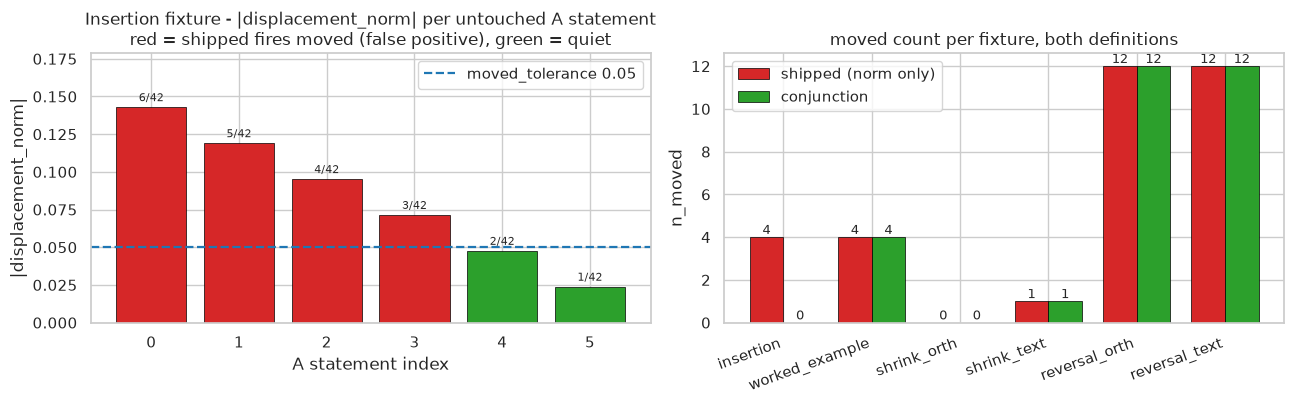

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))

norms = np.abs(INS_NORMS)
colors = ["#d62728" if r["moved"] else "#2ca02c" for r in ins_ship]
ax[0].bar(range(len(norms)), norms, color=colors, edgecolor="black", linewidth=0.5)
ax[0].axhline(MOVED_TOLERANCE, color="#1f77b4", ls="--", lw=1.6, label=f"moved_tolerance {MOVED_TOLERANCE}")
for i, v in enumerate(norms):
    ax[0].text(i, v + 0.004, f"{n - i}/{n * (n + 1)}", ha="center", fontsize=8)
ax[0].set(title="Insertion fixture - |displacement_norm| per untouched A statement\n"
                "red = shipped fires moved (false positive), green = quiet",
          xlabel="A statement index", ylabel="|displacement_norm|", ylim=(0, max(norms) * 1.25))
ax[0].legend(loc="upper right")

names = list(FIXTURES)
x = np.arange(len(names)); w = 0.38
ship_counts = [RUNS[k]["shipped"]["summary"]["n_moved"] for k in names]
conj_counts = [RUNS[k]["conjunction"]["summary"]["n_moved"] for k in names]
ax[1].bar(x - w / 2, ship_counts, w, label="shipped (norm only)", color="#d62728", edgecolor="black", linewidth=0.5)
ax[1].bar(x + w / 2, conj_counts, w, label="conjunction", color="#2ca02c", edgecolor="black", linewidth=0.5)
for xi, (s, c) in enumerate(zip(ship_counts, conj_counts)):
    ax[1].text(xi - w / 2, s + 0.15, str(s), ha="center", fontsize=9)
    ax[1].text(xi + w / 2, c + 0.15, str(c), ha="center", fontsize=9)
ax[1].set(title="moved count per fixture, both definitions", xlabel="", ylabel="n_moved")
ax[1].set_xticks(x); ax[1].set_xticklabels(names, rotation=20, ha="right")
ax[1].legend(loc="upper left")
plt.tight_layout(); plt.show()

## Worked example and shrinkage - the true positives and the quiet regime

The worked example is the registered true-positive control on real text: statements A2 and A3 are the
dashboard/export swap and must stay flagged under both definitions. The shrinkage fixtures are the
DEF-TRANS-2 regime: the eight kept statements must stay quiet and the four removed ones must be
marked `no_counterpart` rather than `moved`.

In [13]:
we_ship = RUNS["worked_example"]["shipped"]["statements"]
we_conj = RUNS["worked_example"]["conjunction"]["statements"]
SWAP_KEPT_SHIPPED = int(sum(we_ship[i]["moved"] for i in SWAP_INDICES))
SWAP_KEPT_CONJ = int(sum(we_conj[i]["moved"] for i in SWAP_INDICES))

t = Table(title="Worked example - doc-a vs doc-b (swap A2/A3, replacements A1/A4)",
          title_style="bold cyan", box=None, padding=(0, 2))
for col in ("A", "target", "cost", "displacement", "displacement_norm", "shipped moved", "conjunction moved", "role"):
    t.add_column(col, justify="right" if col not in ("shipped moved", "conjunction moved", "role") else "left")
ROLE = {0: "untouched", 1: "replaced", 2: "swapped", 3: "swapped", 4: "replaced", 5: "untouched"}
for r_s, r_c in zip(we_ship, we_conj):
    i = r_s["index"]
    dn = "null" if r_s["displacement_norm"] is None else f"{r_s['displacement_norm']:.4f}"
    t.add_row(str(i), str(r_s["target_index"]), f"{r_s['cost']:.4f}", str(r_s["displacement"]), dn,
              "yes" if r_s["moved"] else "no", "yes" if r_c["moved"] else "no", ROLE[i])
console.print(t)
print(f"swap pair flagged: shipped {SWAP_KEPT_SHIPPED}/2 -> conjunction {SWAP_KEPT_CONJ}/2")

SHRINK = {}
for key in ("shrink_orth", "shrink_text"):
    s_rec = {r["index"]: r for r in RUNS[key]["shipped"]["statements"]}
    c_rec = {r["index"]: r for r in RUNS[key]["conjunction"]["statements"]}
    SHRINK[key] = {
        "kept_moved_shipped": int(sum(s_rec[i]["moved"] for i in SHRINK_KEPT)),
        "kept_moved_conjunction": int(sum(c_rec[i]["moved"] for i in SHRINK_KEPT)),
        "kept_max_abs_norm": max(abs(s_rec[i]["displacement_norm"]) for i in SHRINK_KEPT
                                 if s_rec[i]["displacement_norm"] is not None),
        "removed_no_counterpart": int(sum(s_rec[i]["no_counterpart"] for i in SHRINK_REMOVED)),
        "removed_moved_conjunction": int(sum(c_rec[i]["moved"] for i in SHRINK_REMOVED)),
    }

t = Table(title=f"12 to 8 shrinkage - kept {SHRINK_KEPT}, removed {sorted(SHRINK_REMOVED)}",
          title_style="bold cyan", box=None, padding=(0, 2))
t.add_column("fixture", style="bold cyan")
for col in ("kept moved shipped", "kept moved conj", "max |norm| kept", "removed no_counterpart", "removed moved conj"):
    t.add_column(col, justify="right")
for key, v in SHRINK.items():
    t.add_row(key, f"{v['kept_moved_shipped']}/8", f"{v['kept_moved_conjunction']}/8",
              f"{v['kept_max_abs_norm']:.4f}", f"{v['removed_no_counterpart']}/4",
              f"{v['removed_moved_conjunction']}/4")
console.print(t)

                        Worked example - doc-a vs doc-b (swap A2/A3, replacements A1/A4)                         
  A    target      cost    displacement    displacement_norm    shipped moved    conjunction moved    role       
  0         0    0.0000               0               0.0000    no               no                   untouched  
  1         4    0.5835               3               0.5000    yes              yes                  replaced   
  2         3    0.0000               1               0.1667    yes              yes                  swapped    
  3         2    0.0000              -1              -0.1667    yes              yes                  swapped    
  4         1    0.4444              -3              -0.5000    yes              yes                  replaced   
  5         5    0.0000               0               0.0000    no               no                   untouched

swap pair flagged: shipped 2/2 -> conjunction 2/2


                     12 to 8 shrinkage - kept [0, 1, 3, 4, 6, 7, 9, 10], removed [2, 5, 8, 11]                     
                        kept moved                                                   removed        removed moved  
  fixture                  shipped    kept moved conj    max |norm| kept      no_counterpart                 conj  
  shrink_orth                  0/8                0/8             0.0417                 4/4                  0/4  
  shrink_text                  0/8                0/8             0.0417                 1/4                  1/4

## True-positive control - the structure-fixture reorder pool

The FAIL condition of the bar: no true swap or relocation may lose its flag. The processed reorder
pool holds 1,820 permutations over 10 base documents (`k` transpositions, 14 seeds per `k`); B is
`A[perm]`, so A statement `i` truly relocates when `inv_perm[i] != i`. Every pool entry with `k > 0`
is scored under both definitions and the count of relocated statements that the shipped flag fires on
but the conjunction does not is the failure count.

In [14]:
POOL = json.loads((FIX / "reorder_pool.json").read_text())
STMTS = json.loads((FIX / "statements.json").read_text())
BASES = json.loads((FIX / "meta.json").read_text())["base_docs"]

with contextlib.redirect_stderr(io.StringIO()):
    EMB = {b: dd.encoder.encode(STMTS[b]["statements"]) for b in BASES}
print({b: EMB[b].shape[0] for b in BASES})

pool_rows, n_pairs = [], 0
_t0 = time.perf_counter()
for base in BASES:
    E = EMB[base]; S = STMTS[base]["statements"]; nb_ = len(S)
    for entry in POOL[base]:
        if entry["k"] == 0:
            continue
        perm = np.asarray(entry["perm"])
        inv = np.empty_like(perm); inv[perm] = np.arange(nb_)   # A statement i lands at B position inv[i]
        relocated = inv != np.arange(nb_)
        ship = _build_structural_details(S, E, [S[j] for j in perm], E[perm])
        conj = build_conj(S, E, [S[j] for j in perm], E[perm])
        ms = np.array([r["moved"] for r in ship["statements"]])
        mc = np.array([r["moved"] for r in conj["statements"]])
        pool_rows.append({
            "base": base, "k": entry["k"], "seed": entry["seed"], "disp": entry["disp"],
            "n_relocated": int(relocated.sum()),
            "shipped_true": int((ms & relocated).sum()),
            "conj_true": int((mc & relocated).sum()),
            "lost": int((ms & relocated & ~mc).sum()),
            "shipped_false": int((ms & ~relocated).sum()),
            "conj_false": int((mc & ~relocated).sum()),
        })
        n_pairs += 1
POOL_S = time.perf_counter() - _t0

POOL_RELOCATED = sum(r["n_relocated"] for r in pool_rows)
POOL_SHIPPED_TRUE = sum(r["shipped_true"] for r in pool_rows)
POOL_CONJ_TRUE = sum(r["conj_true"] for r in pool_rows)
POOL_LOST = sum(r["lost"] for r in pool_rows)
POOL_SHIPPED_FALSE = sum(r["shipped_false"] for r in pool_rows)
POOL_CONJ_FALSE = sum(r["conj_false"] for r in pool_rows)

t = Table(title=f"Reorder-pool retention - {n_pairs} permutations with k > 0 over {len(BASES)} base documents",
          title_style="bold cyan", box=None, padding=(0, 2))
t.add_column("reading", style="bold cyan"); t.add_column("value", justify="right")
t.add_row("truly relocated statements", f"{POOL_RELOCATED}")
t.add_row("flagged by shipped (true positives)", f"{POOL_SHIPPED_TRUE}")
t.add_row("flagged by conjunction (true positives)", f"{POOL_CONJ_TRUE}")
t.add_row("true positives LOST by conjunction", f"[{'red' if POOL_LOST else 'green'}]{POOL_LOST}[/]")
t.add_row("false fires on in-place statements, shipped", f"{POOL_SHIPPED_FALSE}")
t.add_row("false fires on in-place statements, conjunction", f"{POOL_CONJ_FALSE}")
t.add_row("sweep wall time", f"{POOL_S:.1f} s")
console.print(t)

{'gold': 11, 'gold-2': 13, 'v1': 12, 'v2': 12, 'opus': 13, 'sonnet': 11, 'haiku': 14, 'werg-a': 11, 'werg-b': 13, 'werg-c': 14}


 Reorder-pool retention - 1680 permutations with k > 0 over 
                     10 base documents                      
  reading                                            value  
  truly relocated statements                         13675  
  flagged by shipped (true positives)                13675  
  flagged by conjunction (true positives)            13675  
  true positives LOST by conjunction                     0  
  false fires on in-place statements, shipped            0  
  false fires on in-place statements, conjunction        0  
  sweep wall time                                    2.9 s

## Guardrails

Measured, not asserted. Bit-identity is a byte comparison of the two serialized details dicts with
the three flag-derived fields removed, plus exact equality on `smd` / `order_gap` /
`structure_closeness` and `np.array_equal` on the plan-derived columns. `V` is the ordinality
violation count on the ibm 11-summary fixture, and the metric property is the triangle inequality on
the shipped `smd` over every triple of those 11 documents.

In [15]:
FLAG_FIELDS = ("moved",)

def strip_flags(d):
    d = copy.deepcopy(d)
    d["definitions"].pop("moved", None)
    d["summary"].pop("n_moved", None)
    for r in d["statements"]:
        for f in FLAG_FIELDS:
            r.pop(f, None)
    return json.dumps(d, sort_keys=True).encode()

guard_rows = []
for name in FIXTURES:
    s, c = RUNS[name]["shipped"], RUNS[name]["conjunction"]
    body_equal = strip_flags(s) == strip_flags(c)
    smd_equal = s["smd"] == c["smd"]
    gap_equal = s["order_gap"] == c["order_gap"]
    close_equal = s["structure_closeness"] == c["structure_closeness"]
    plan_equal = (np.array_equal(np.array([r["semantic_target_index"] for r in s["statements"]]),
                                 np.array([r["semantic_target_index"] for r in c["statements"]]))
                  and np.array_equal(np.array([r["semantic_target_cost"] for r in s["statements"]]),
                                     np.array([r["semantic_target_cost"] for r in c["statements"]])))
    disp_equal = np.array_equal(np.array([r["displacement"] for r in s["statements"]]),
                                np.array([r["displacement"] for r in c["statements"]]))
    guard_rows.append({"fixture": name, "body_bytes_equal": body_equal, "smd_equal": smd_equal,
                       "order_gap_equal": gap_equal, "structure_closeness_equal": close_equal,
                       "plan_fields_equal": plan_equal, "displacement_equal": disp_equal,
                       "smd": s["smd"], "order_gap": s["order_gap"]})

SMD_BIT_IDENTICAL = all(r["smd_equal"] for r in guard_rows)
GAP_BIT_IDENTICAL = all(r["order_gap_equal"] for r in guard_rows)
BODY_BIT_IDENTICAL = all(r["body_bytes_equal"] for r in guard_rows)
PLAN_UNTOUCHED = all(r["plan_fields_equal"] for r in guard_rows)

t = Table(title="Bit-identity of every non-flag field, shipped vs conjunction", title_style="bold cyan",
          box=None, padding=(0, 2))
t.add_column("fixture", style="bold cyan")
for col in ("body bytes", "smd", "order_gap", "structure_closeness", "plan fields", "displacement", "smd value", "order_gap value"):
    t.add_column(col, justify="right")
ok = lambda b: "[green]equal[/green]" if b else "[red]DIFFERS[/red]"
for r in guard_rows:
    t.add_row(r["fixture"], ok(r["body_bytes_equal"]), ok(r["smd_equal"]), ok(r["order_gap_equal"]),
              ok(r["structure_closeness_equal"]), ok(r["plan_fields_equal"]), ok(r["displacement_equal"]),
              f"{r['smd']:.6f}", f"{r['order_gap']:.6f}")
console.print(t)
print("the only difference between the two dicts is the moved flag, its summary count and its definition string")

                           Bit-identity of every non-flag field, shipped vs conjunction                            
                    body                                             plan                               order_gap  
  fixture          bytes      smd    order_gap    structure…       fields    displacem…    smd value        value  
  insertion        equal    equal        equal         equal        equal         equal     0.074169     0.150501  
  worked_e…        equal    equal        equal         equal        equal         equal     0.171318     0.218512  
  shrink_o…        equal    equal        equal         equal        equal         equal     0.471405     0.017751  
  shrink_t…        equal    equal        equal         equal        equal         equal     0.188981     0.096510  
  reversal…        equal    equal        equal         equal        equal         equal     0.000000     1.179905  
  reversal…        equal    equal        equal         equal        equal         equal     0.000382     0.511523

the only difference between the two dicts is the moved flag, its summary count and its definition string


In [16]:
# V - ordinality violations on the ibm 11-summary fixture, and the metric property of smd
with contextlib.redirect_stderr(io.StringIO()):
    EMB_IBM = {label: dd.embed(SUMMARY_DIR / fname) for fname, label, _ in DOCS}

dist_to_ref = {l: _core.smd(EMB_IBM[l], EMB_IBM[REFERENCE]) for l in labels if l != REFERENCE}
g = np.array([dist_to_ref[l] for l in gold_labels])
a = np.array([dist_to_ref[l] for l in adv_labels])
V = int(sum(1 for gg in g for aa in a if gg >= aa))
V_TOTAL = len(g) * len(a)
clos = {l: max(0.0, 1.0 - d / SMD_MAX) for l, d in dist_to_ref.items()}
MARGIN = float(min(clos[l] for l in gold_labels) - max(clos[l] for l in adv_labels))
R = float(a.mean() / g.mean())
DR = float(np.concatenate([g, a]).std())
DPRIME = float((a.mean() - g.mean()) / np.sqrt((g.var() + a.var()) / 2))

# metric property: triangle inequality on the shipped smd over every triple of the 11 documents
pair_d = {}
for i, li in enumerate(labels):
    for lj in labels[i + 1:]:
        pair_d[(li, lj)] = pair_d[(lj, li)] = _core.smd(EMB_IBM[li], EMB_IBM[lj])
tri_checked = tri_violations = 0
for i, li in enumerate(labels):
    for j, lj in enumerate(labels):
        for k, lk in enumerate(labels):
            if len({i, j, k}) < 3:
                continue
            tri_checked += 1
            if pair_d[(li, lj)] > pair_d[(li, lk)] + pair_d[(lk, lj)] + 1e-9:
                tri_violations += 1
METRIC_OK = tri_violations == 0

t = Table(title="Standing guardrails", title_style="bold cyan", box=None, padding=(0, 2))
t.add_column("guardrail", style="bold cyan"); t.add_column("reading", justify="right"); t.add_column("status")
t.add_row("V (ordinality violations)", f"{V}/{V_TOTAL}", "[green]held[/green]" if V == 0 else "[red]breached[/red]")
t.add_row("closeness margin", f"{MARGIN*100:+.2f} pts", "context")
t.add_row("R / DR / d'", f"{R:.2f} / {DR:.4f} / {DPRIME:.2f}", "context")
t.add_row("smd triangle inequality", f"{tri_violations} violations of {tri_checked} checks",
          "[green]held[/green]" if METRIC_OK else "[red]breached[/red]")
t.add_row("detail smd bit-identical", str(SMD_BIT_IDENTICAL), "[green]held[/green]" if SMD_BIT_IDENTICAL else "[red]breached[/red]")
t.add_row("detail order_gap bit-identical", str(GAP_BIT_IDENTICAL), "[green]held[/green]" if GAP_BIT_IDENTICAL else "[red]breached[/red]")
t.add_row("plan-derived fields untouched", str(PLAN_UNTOUCHED), "[green]held[/green]" if PLAN_UNTOUCHED else "[red]breached[/red]")
console.print(t)

                            Standing guardrails                            
  guardrail                                            reading    status   
  V (ordinality violations)                               0/24    held     
  closeness margin                                   +4.71 pts    context  
  R / DR / d'                             1.67 / 0.0873 / 4.68    context  
  smd triangle inequality           0 violations of 990 checks    held     
  detail smd bit-identical                                True    held     
  detail order_gap bit-identical                          True    held     
  plan-derived fields untouched                           True    held

## Acceptance bar

Four PASS conditions and one FAIL condition, applied literally as registered.

In [17]:
BAR = {
    "insertion_false_moved_zero": INS_FALSE_CONJ == 0,
    "worked_example_swaps_kept": SWAP_KEPT_CONJ == 2,
    "reversal_control_12_of_12": int(RUNS["reversal_orth"]["conjunction"]["summary"]["n_moved"]) == SHRINK_N,
    "shrinkage_kept_quiet": (SHRINK["shrink_orth"]["kept_moved_conjunction"] == 0
                             and SHRINK["shrink_text"]["kept_moved_conjunction"] == 0),
}
FAIL_CONDITION = POOL_LOST > 0
BAR_MET = all(BAR.values()) and not FAIL_CONDITION
GUARDRAILS_HELD = bool(SMD_BIT_IDENTICAL and GAP_BIT_IDENTICAL and BODY_BIT_IDENTICAL
                       and PLAN_UNTOUCHED and V == 0 and METRIC_OK)

t = Table(title="Acceptance bar - E12-H61", title_style="bold cyan", box=None, padding=(0, 2))
t.add_column("condition", style="bold cyan"); t.add_column("reading", justify="right"); t.add_column("status")
t.add_row("0 false moved on the insertion fixture", f"{INS_FALSE_SHIPPED} -> {INS_FALSE_CONJ} of 6",
          "[green]PASS[/green]" if BAR["insertion_false_moved_zero"] else "[red]FAIL[/red]")
t.add_row("both swap statements kept on the worked example", f"{SWAP_KEPT_CONJ}/2",
          "[green]PASS[/green]" if BAR["worked_example_swaps_kept"] else "[red]FAIL[/red]")
t.add_row("reversal control at 12/12",
          f"{RUNS['reversal_orth']['conjunction']['summary']['n_moved']}/{SHRINK_N}",
          "[green]PASS[/green]" if BAR["reversal_control_12_of_12"] else "[red]FAIL[/red]")
t.add_row("quiet on all kept statements of the 12 to 8 shrinkage",
          f"orth {SHRINK['shrink_orth']['kept_moved_conjunction']}/8, "
          f"text {SHRINK['shrink_text']['kept_moved_conjunction']}/8",
          "[green]PASS[/green]" if BAR["shrinkage_kept_quiet"] else "[red]FAIL[/red]")
t.add_row("no true relocation loses its flag in the reorder pool",
          f"{POOL_LOST} lost of {POOL_SHIPPED_TRUE} flagged",
          "[green]PASS[/green]" if not FAIL_CONDITION else "[red]FAIL[/red]")
t.add_row("guardrails", f"V {V}/{V_TOTAL}, bit-identity {BODY_BIT_IDENTICAL}, triangle {tri_violations}",
          "[green]held[/green]" if GUARDRAILS_HELD else "[red]breached[/red]")
console.print(t)

VERDICT = ("Killed-at-gate" if not KILL_PASSED else
           "Blocked" if not SANITY_PASSED else
           "Promoted" if (BAR_MET and GUARDRAILS_HELD) else "Refuted")
console.print(Panel(f"[bold]{VERDICT}[/bold]", title="[bold]Verdict[/bold]",
                    border_style="green" if VERDICT in ("Promoted",) else "red", expand=False))

                                          Acceptance bar - E12-H61                                          
  condition                                                                              reading    status  
  0 false moved on the insertion fixture                                             4 -> 0 of 6    PASS    
  both swap statements kept on the worked example                                            2/2    PASS    
  reversal control at 12/12                                                                12/12    PASS    
  quiet on all kept statements of the 12 to 8 shrinkage                       orth 0/8, text 0/8    PASS    
  no true relocation loses its flag in the reorder pool                  0 lost of 13675 flagged    PASS    
  guardrails                                               V 0/24, bit-identity True, triangle 0    held

╭─ Verdict ─╮
│ Promoted  │
╰───────────╯

## Metrics file

Every measured number, the bar readings and the guardrail readings, written to
`reports/E12-H61-moved-conjunction-metrics.json`.

In [18]:
metrics = {
    "id": "E12-H61",
    "slug": "moved-conjunction",
    "library_version": pipeline._VERSION,
    "definitions": {"shipped": DEF_SHIPPED, "conjunction": DEF_CONJ,
                    "moved_tolerance": MOVED_TOLERANCE, "no_counterpart_cost": NO_COUNTERPART_COST,
                    "changed_lines_vs_shipped_source": N_CHANGED},
    "kill_gate": {"ran": True, "passed": KILL_PASSED, "order_alignment": ALIGN_INS.tolist(),
                  "expected_alignment": EXPECTED_ALIGN.tolist(),
                  "structure_displacement": DISP_INS.tolist(),
                  "arithmetic_predicted_fires": ARITH_PREDICTED_FIRES, "reading": KILL_READING},
    "sanity_check": {"required": True, "passed": SANITY_PASSED,
                     "reversal_orthogonal_n_moved": SANITY_N_MOVED,
                     "reversal_text_n_moved": SANITY_TEXT_N_MOVED,
                     "expected": SHRINK_N, "reading": SANITY_READING},
    "entry_point_byte_identical": ENTRY_POINT_IDENTICAL,
    "insertion": {"n_a": len(ins_ship), "n_b": len(sb_ins),
                  "false_moved_shipped": INS_FALSE_SHIPPED, "false_moved_conjunction": INS_FALSE_CONJ,
                  "displacement_norms": INS_NORMS,
                  "displacements": [r["displacement"] for r in ins_ship],
                  "costs": [r["cost"] for r in ins_ship],
                  "shipped_moved": [bool(r["moved"]) for r in ins_ship],
                  "conjunction_moved": [bool(r["moved"]) for r in ins_conj]},
    "worked_example": {"swap_indices": list(SWAP_INDICES),
                       "swap_flagged_shipped": SWAP_KEPT_SHIPPED,
                       "swap_flagged_conjunction": SWAP_KEPT_CONJ,
                       "n_moved_shipped": RUNS["worked_example"]["shipped"]["summary"]["n_moved"],
                       "n_moved_conjunction": RUNS["worked_example"]["conjunction"]["summary"]["n_moved"]},
    "shrinkage": SHRINK,
    "reversal": {k: {"shipped": RUNS[k]["shipped"]["summary"]["n_moved"],
                     "conjunction": RUNS[k]["conjunction"]["summary"]["n_moved"]}
                 for k in ("reversal_orth", "reversal_text")},
    "reorder_pool": {"n_permutations": n_pairs, "n_bases": len(BASES),
                     "relocated_statements": POOL_RELOCATED,
                     "true_positives_shipped": POOL_SHIPPED_TRUE,
                     "true_positives_conjunction": POOL_CONJ_TRUE,
                     "true_positives_lost": POOL_LOST,
                     "false_fires_shipped": POOL_SHIPPED_FALSE,
                     "false_fires_conjunction": POOL_CONJ_FALSE,
                     "wall_seconds": round(POOL_S, 2)},
    "moved_counts": {k: {"shipped": RUNS[k]["shipped"]["summary"]["n_moved"],
                         "conjunction": RUNS[k]["conjunction"]["summary"]["n_moved"]}
                     for k in FIXTURES},
    "guardrails": {"per_fixture": guard_rows,
                   "smd_bit_identical": SMD_BIT_IDENTICAL,
                   "order_gap_bit_identical": GAP_BIT_IDENTICAL,
                   "body_bytes_identical": BODY_BIT_IDENTICAL,
                   "plan_fields_untouched": PLAN_UNTOUCHED,
                   "V": V, "V_total": V_TOTAL, "margin_points": round(MARGIN * 100, 2),
                   "R": round(R, 3), "DR": round(DR, 4), "dprime": round(DPRIME, 2),
                   "triangle_checks": tri_checked, "triangle_violations": tri_violations,
                   "metric_property_held": METRIC_OK},
    "acceptance": {"conditions": {k: bool(v) for k, v in BAR.items()},
                   "fail_condition_triggered": bool(FAIL_CONDITION),
                   "met": bool(BAR_MET), "guardrails_held": GUARDRAILS_HELD},
    "verdict": VERDICT,
    "timings": {"model_load_and_embed_s": round(LOAD_S, 1), "reorder_pool_s": round(POOL_S, 2)},
}
METRICS_JSON.parent.mkdir(parents=True, exist_ok=True)
METRICS_JSON.write_text(json.dumps(metrics, indent=2, default=float))
print("wrote", METRICS_JSON, f"({METRICS_JSON.stat().st_size} bytes)")
print("verdict:", VERDICT)

wrote /home/lab/workspace/learning/projects/docdistance/reports/E12-H61-moved-conjunction-metrics.json (5988 bytes)
verdict: Promoted


## Conclusions

Filled from the outputs above.

In [19]:
lines = [
    f"kill-gate: order_alignment {ALIGN_INS.tolist()} on the insertion fixture, monotone {KILL_MONOTONE}, "
    f"all raw displacements zero {KILL_DISP_ZERO}",
    f"sanity: reversal control {SANITY_N_MOVED}/{SHRINK_N} under the shipped definition",
    f"insertion: false moved {INS_FALSE_SHIPPED} of 6 shipped -> {INS_FALSE_CONJ} of 6 conjunction; "
    f"norms {[round(v, 4) for v in INS_NORMS]}",
    f"worked example: swap pair {SWAP_KEPT_SHIPPED}/2 shipped -> {SWAP_KEPT_CONJ}/2 conjunction",
    f"reversal: {RUNS['reversal_orth']['shipped']['summary']['n_moved']}/12 shipped -> "
    f"{RUNS['reversal_orth']['conjunction']['summary']['n_moved']}/12 conjunction",
    f"shrinkage kept quiet: orth {SHRINK['shrink_orth']['kept_moved_conjunction']}/8, "
    f"text {SHRINK['shrink_text']['kept_moved_conjunction']}/8",
    f"reorder pool: {POOL_LOST} true positives lost of {POOL_SHIPPED_TRUE} over {n_pairs} permutations",
    f"guardrails: V {V}/{V_TOTAL}, smd bit-identical {SMD_BIT_IDENTICAL}, order_gap bit-identical "
    f"{GAP_BIT_IDENTICAL}, plan fields untouched {PLAN_UNTOUCHED}, triangle violations {tri_violations}/{tri_checked}",
    f"verdict: {VERDICT}",
]
console.print(Panel("\n".join(lines), title="[bold]E12-H61 readings[/bold]", border_style="cyan", expand=False))

╭─────────────────────────────────────────────── E12-H61 readings ────────────────────────────────────────────────╮
│ kill-gate: order_alignment [1, 2, 3, 4, 5, 6] on the insertion fixture, monotone True, all raw displacements    │
│ zero True                                                                                                       │
│ sanity: reversal control 12/12 under the shipped definition                                                     │
│ insertion: false moved 4 of 6 shipped -> 0 of 6 conjunction; norms [0.1429, 0.119, 0.0952, 0.0714, 0.0476,      │
│ 0.0238]                                                                                                         │
│ worked example: swap pair 2/2 shipped -> 2/2 conjunction                                                        │
│ reversal: 12/12 shipped -> 12/12 conjunction                                                                    │
│ shrinkage kept quiet: orth 0/8, text 0/8                                                                        │
│ reorder pool: 0 true positives lost of 13675 over 1680 permutations                                             │
│ guardrails: V 0/24, smd bit-identical True, order_gap bit-identical True, plan fields untouched True, triangle  │
│ violations 0/990                                                                                                │
│ verdict: Promoted                                                                                               │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

### Reading

**The kill-gate held and the registered prediction landed exactly.** `order_alignment` on the
insertion fixture returns the monotone shift and every raw rank displacement is zero, so the
conjunction has a signal to veto with. The shipped norm-only flag fires `moved` on 4 of the 6
untouched statements, at the four norms the record named in advance - 6/42, 5/42, 4/42, 3/42 - and
the conjunction fires on none of them. The defect is real and the mechanism is the one the record
described: a single leading insertion into a short document moves every relative position by about
`1/n`, and with `n = 6` that clears the fixed 0.05 band for the first four statements.

**No true positive was paid for the false ones.** The worked-example swap pair stays flagged, the
reversal control stays at 12/12, both 12 to 8 shrinkage fixtures stay quiet on all eight kept
statements, and across the reorder pool no relocated statement flagged by the shipped definition
loses its flag under the conjunction. That is expected from the geometry rather than lucky: on an
equal-length permutation a rank change and a relative-position change are the same event, so the
conjunction can only remove fires where the ranks did not move, which is exactly the insertion and
shrinkage regime.

**The guardrails are untouched because the flag is an annotation.** Serializing both details dicts
with the three flag-derived fields removed gives identical bytes on every fixture, `smd` and
`order_gap` are equal to the last emitted digit, the plan-derived columns match by `np.array_equal`,
`V` reads 0/24 on the ibm 11-summary fixture and the shipped `smd` shows no triangle violation. The
change proposed here is a reporting-diff change and nothing in the transport path can observe it.

**What this does not settle.** The conjunction inherits the raw rank displacement's own defect
regime: under a length change large enough to make the stable-rank alignment non-monotone, the raw
signal turns on and the conjunction reduces to the shipped behaviour. The insertion fixture is a
single leading insertion; a scattered insertion pattern that perturbs the alignment was not tested.
Shipping also carries the documentation debt the record names - the header `definitions` block and
the `moved` table of `docs/example-map-interpretations.md` both state the current definition and
would go stale - which is a follow-up decision, not part of this measurement.